# Mining Urban Dining Sentiments in New Cairo: Dataset, Data Quality and EDA

This notebook describes the dataset (Google Maps restaurants and reviews for Fifth Settlement, Rehab and First Settlement in Cairo), cleans the restaurant metadata, and analyzes its quality. The review-text analysis and the NLP preprocessing pipeline are in the later sections.

## Dataset

| Item | Description |
|---|---|
| **Dataset name** | Cairo (New Cairo) Restaurants and Reviews, Google Maps |
| **Sources** | Google Maps place pages and public reviews |
| **Link** | <https://apify.com/compass/crawler-google-places> |
| **Records** | 684 places (290 Fifth Settlement, 394 Rehab/First Settlement) and 6,120 reviews, of which 2,855 have written text and 3,265 are rating-only. 306 places have reviews. |
| **Languages** | Arabic (mostly Egyptian dialect), English, Arabizi (Arabic written in Latin letters), and mixed Arabic/English |
| **Collection method** | Apify scrapers: `compass/crawler-google-places` for places (many narrow searches by cuisine and area, in English and Arabic), and `compass/google-maps-reviews-scraper` for reviews. Scrape date: 2026-10-25. Reviews are Google reviews dated 2019 to 2026. |
| **Place fields (examples)** | `placeId`, `title`, `categoryName`, `address`, `totalScore`, `reviewsCount`, `phone`, `website`, `menu`, `openingHours`, `location` (latitude/longitude) |
| **Review fields** | `reviewId`, `placeId`, `title`, `text`, `stars`, `publishedAtDate`, `originalLanguage`, `responseFromOwnerText`, `textTranslated` |
| **Target label** | Sentiment derived from the 1-5 star rating (weak labels): 1-2 negative, 3 neutral, 4-5 positive. A hand-annotated gold subset is planned for Milestone 2. |
| **Join key** | `placeId` links each review to its restaurant |
| **Privacy** | Reviewer names, IDs, photos and URLs are dropped. Raw reviews are shared only with the instructor. |

The data has two parts. The place metadata is structured and needs data cleaning (this section), and the review text needs the NLP pipeline (later sections).

In [31]:
import glob, json, os
import pandas as pd

def _find(patterns):
    return sorted({os.path.abspath(f) for p in patterns for b in ("/content", ".")
                   for f in glob.glob(os.path.join(b, p))})
def _load(p):
    with open(p, encoding="utf-8") as f:
        return pd.DataFrame(json.load(f))

place_files  = _find(["*discovery*.json"])
review_files = _find(["*eviews*fifth*.json", "*ehab*review*.json"])
_places  = pd.concat([_load(p) for p in place_files], ignore_index=True).drop_duplicates("placeId")
_reviews = pd.concat([_load(p) for p in review_files], ignore_index=True).drop_duplicates("reviewId")
_has_text = _reviews["text"].notna() & (_reviews["text"].str.strip() != "")
dates = pd.to_datetime(_reviews["publishedAtDate"], errors="coerce", utc=True)

pd.DataFrame({
    "Item": ["Places (restaurants)", "Place fields (raw)", "Reviews (all)", "Reviews with written text",
             "Reviews without text (rating only)", "Places that have reviews", "Review dates"],
    "Value": [f"{len(_places):,}", _places.shape[1], f"{len(_reviews):,}",
              f"{_has_text.sum():,} ({_has_text.mean():.0%})", f"{(~_has_text).sum():,}",
              _reviews["placeId"].nunique(), f"{dates.min():%Y-%m-%d} to {dates.max():%Y-%m-%d}"]})

,Item,Value
0,Places (restaurants),684
1,Place fields (raw),73
2,Reviews (all),"6,120"
3,Reviews with written text,"2,855 (47%)"
4,Reviews without text (rating only),"3,265"
5,Places that have reviews,306
6,Review dates,2019-01-09 to 2026-10-25


Import libraries

In [3]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

print("Libraries imported successfully!")

Libraries imported successfully!


Step 4 — Load and combine the JSON files

In [4]:
def load_json(filename):

    with open(filename, 'r', encoding='utf-8') as file:
        data = json.load(file)

    # Handle different JSON structures
    if isinstance(data, list):
        return pd.DataFrame(data)

    elif isinstance(data, dict):
        if 'data' in data and isinstance(data['data'], list):
            return pd.DataFrame(data['data'])

        return pd.DataFrame([data])

    else:
        raise ValueError(f"Unexpected JSON structure in {filename}")


# Load Fifth Settlement
df_fifth = load_json('fifth-settlement-discovery.json')

# Load Rehab / First Settlement
df_rehab = load_json('Rehab-discovery.json')


# Combine both datasets
df_places = pd.concat(
    [df_fifth, df_rehab],
    ignore_index=True
)

print("Dataset loaded successfully!")
print("Total places:", len(df_places))

Dataset loaded successfully!
Total places: 684


In [5]:
df_places

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re

In [6]:
df_fifth['source_file'] = 'fifth-settlement-discovery.json'
df_rehab['source_file'] = 'Rehab-discovery.json'

df_places_raw = pd.concat(
    [df_fifth, df_rehab],
    ignore_index=True
)

In [7]:
df_places.head()

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re

Dataset Information

In [8]:
print("Dataset shape:", df_places.shape)

print("\nColumn names:")
print(df_places.columns.tolist())

print("\nFirst 5 rows:")
display(df_places.head())

print("\nData types:")
display(df_places.dtypes)

print("\nDataset information:")
df_places.info()

Dataset shape: (684, 73)

Column names:
['title', 'subTitle', 'description', 'ownerDescription', 'price', 'categoryName', 'address', 'neighborhood', 'street', 'city', 'postalCode', 'state', 'countryCode', 'phone', 'phoneUnformatted', 'claimThisBusiness', 'location', 'locatedIn', 'floor', 'plusCode', 'menu', 'servicesLink', 'totalScore', 'permanentlyClosed', 'temporarilyClosed', 'placeId', 'categories', 'fid', 'cid', 'reviewsCount', 'reviewsDistribution', 'imagesCount', 'imageCategories', 'scrapedAt', 'reserveTableUrl', 'googleFoodUrl', 'hotelStars', 'hotelDescription', 'checkInDate', 'checkOutDate', 'hotelAds', 'popularTimesLiveText', 'popularTimesLivePercent', 'popularTimesHistogram', 'openingHours', 'wasOpenAtScrapeTime', 'peopleAlsoSearch', 'placesTags', 'reviewsTags', 'gasPrices', 'url', 'searchPageUrl', 'searchString', 'language', 'rank', 'isAdvertisement', 'imageUrl', 'kgmid', 'businessProfileId', 'additionalInfo', 'questionsAndAnswers', 'webResults', 'tableReservationLinks', 'ta

,title,subTitle,description,ownerDescription,price,categoryName,address,neighborhood,street,city,postalCode,state,countryCode,phone,phoneUnformatted,claimThisBusiness,location,locatedIn,floor,plusCode,menu,servicesLink,totalScore,permanentlyClosed,temporarilyClosed,placeId,categories,fid,cid,reviewsCount,reviewsDistribution,imagesCount,imageCategories,scrapedAt,reserveTableUrl,googleFoodUrl,hotelStars,hotelDescription,checkInDate,checkOutDate,hotelAds,popularTimesLiveText,popularTimesLivePercent,popularTimesHistogram,openingHours,wasOpenAtScrapeTime,peopleAlsoSearch,placesTags,reviewsTags,gasPrices,url,searchPageUrl,searchString,language,rank,isAdvertisement,imageUrl,kgmid,businessProfileId,additionalInfo,questionsAndAnswers,webResults,tableReservationLinks,tableReservationProviders,bookingLinks,restaurantData,ownerUpdates,imageUrls,reviews,leadsEnrichment,updatesFromCustomers,website,additionalOpeningHours
0,Yorki Pizza,None,None,None,None,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",None,"2C28+3PW Zeina Mall, شارع ١٦",New Cairo 1,11865,Cairo Governorate,EG,+20 15 59816169,+201559816169,True,"{'lat': 30.0002356, 'lng': 31.4168186}",None,None,None,None,None,3.3,False,False,ChIJe86CavU9WBQRsTtU5ukMwyY,[Pizza restaurant],0x14583df56a82ce7b:0x26c30ce9e6543bb1,2793090392631032753,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",0,[By owner],2026-10-25T17:21:06.686Z,None,None,None,None,None,None,[],None,NaN,{},"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",True,"[{'category': 'People also search for', 'title': 'UNO pizza', 'reviewsCount': 18, 'totalScore': ...",[],[],[],https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,13,False,None,/g/11nh41nw2r,None,"{'Service options': [{'Delivery': True}, {'Takeout': True}, {'Dine-in': True}], 'Popular for': [...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],NaN,NaN,NaN
1,pizza 88,None,None,None,E£200–400,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",None,2C3F+HCJ بجوار شورما حلب,New Cairo 1,None,Cairo Governorate,EG,,,True,"{'lat': 30.0039749, 'lng': 31.4235106}",Twin Plaza mall - new Cairo,None,None,None,None,3.5,False,False,ChIJ5f22KAA9WBQR0kwXXlcbW4U,[Pizza restaurant],0x14583d0028b6fde5:0x855b1b575e174cd2,9609304291979775186,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",0,"[All, Food & drink, Pizza, By owner]",2026-10-25T17:21:08.020Z,None,None,None,None,None,None,[],None,NaN,{},[],None,"[{'category': 'People also search for', 'title': 'Pizza '88 - Mobil Gas Station Concord', 'revie...",[],"[{'title': 'chicks', 'count': 2}, {'title': 'literally', 'count': 2}]",[],https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,"https://www.google.com/maps/search/%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7/@29.99982456925998,31.42053860...",بيتزا,en,12,False,https://gz0.googleusercontent.com/grass-proxy/AIM7gW3FBAxqCGHJtBEN1F_n0pX5qpyF24TUHyaSl_56wYQOtU...,/g/11xrzr4p2w,None,"{'Service options': [{'Takeout': True}, {'Dine-in': True}], 'Popular for': [{'Lunch': True}, {'D...",[],[],[],[],[],{'tableReservationProvider': None},[],[],[],[],"{'text': None, 'language': None, 'postDate': '8 months ago', 'postedBy': {'name': 'Elsayed Elbou...",NaN,NaN
2,Pizza Bob AlTagamoaa,None,None,"Pizza Smells Sea, بيتزا سي فود بريحة البحر","E£200–1,200",Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",None,"امام حي ١, Street 15",New Cairo 1,11856,Cairo Governorate,EG,+20 12 88882764,+201288882764,False,"{'lat': 30.0060522, 'lng': 31.4249543}",None,None,"2C4F+CX New Cairo 1, Egypt",https://linktr.ee/pizza.bob,None,4.0,False,False,ChIJ71zoEgA9WBQRiMecb_IYk-o,[Pizza re


Data types:


,0
title,object
subTitle,object
description,object
ownerDescription,object
price,object
...,...
reviews,object
leadsEnrichment,object
updatesFromCustomers,object
website,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 684 entries, 0 to 683
Data columns (total 73 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   title                      684 non-null    object 
 1   subTitle                   0 non-null      object 
 2   description                33 non-null     object 
 3   ownerDescription           330 non-null    object 
 4   price                      354 non-null    object 
 5   categoryName               682 non-null    object 
 6   address                    684 non-null    object 
 7   neighborhood               69 non-null     object 
 8   street                     650 non-null    object 
 9   city                       684 non-null    object 
 10  postalCode                 332 non-null    object 
 11  state                      684 non-null    object 
 12  countryCode                684 non-null    object 
 13  phone                      6

column priorities

In [9]:
selected_columns = [
    'placeId', 'title',
    'categoryName', 'categories',
    'address', 'city', 'location',
    'totalScore', 'reviewsCount',
    'reviewsDistribution', 'price',
    'phone', 'website', 'url',
    'permanentlyClosed', 'temporarilyClosed',
    'locatedIn', 'openingHours', 'menu',
    'popularTimesHistogram',
    'scrapedAt', 'neighborhood', 'street',
    'description', 'source_file'
]

df_places = df_places_raw[selected_columns].copy()

Verify The Result

In [10]:
print("Dataset shape:", df_places.shape)
print("\nColumns:")
print(df_places.columns.tolist())

df_places.head()

Dataset shape: (684, 25)

Columns:
['placeId', 'title', 'categoryName', 'categories', 'address', 'city', 'location', 'totalScore', 'reviewsCount', 'reviewsDistribution', 'price', 'phone', 'website', 'url', 'permanentlyClosed', 'temporarilyClosed', 'locatedIn', 'openingHours', 'menu', 'popularTimesHistogram', 'scrapedAt', 'neighborhood', 'street', 'description', 'source_file']


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",None,+20 15 59816169,NaN,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,None,"2C28+3PW Zeina Mall, شارع ١٦",None,fifth-settlement-discovery.json
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,,NaN,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,None,2C3F+HCJ بجوار شورما حلب,None,fifth-settlement-discovery.json
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,None,"امام حي ١, Street 15",None,fifth-settlement-discovery.json
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",None,,NaN,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,None,2C3F+JPG,None,fifth-settlement-discovery.json
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,None,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


Data Quality Analysis

In [11]:
print("Duplicate placeIds:", df_places['placeId'].duplicated().sum())

missing_values = df_places.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Count': missing_values,
    'Missing Percentage': (missing_values / len(df_places)) * 100
})

missing_summary = missing_summary.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_summary)

print("Empty titles:", (df_places['title'].astype(str).str.strip() == '').sum())

print("\nPermanently closed:")
print(df_places['permanentlyClosed'].value_counts(dropna=False))

print("\nTemporarily closed:")
print(df_places['temporarilyClosed'].value_counts(dropna=False))

display(df_places[['totalScore', 'reviewsCount']].describe())

Duplicate placeIds: 0


,Missing Count,Missing Percentage
description,651,95.175439
neighborhood,615,89.912281
menu,599,87.573099
locatedIn,523,76.461988
website,402,58.771930
price,330,48.245614
reviewsDistribution,42,6.140351
reviewsCount,42,6.140351
totalScore,42,6.140351
street,34,4.970760


Empty titles: 0

Permanently closed:
permanentlyClosed
False    684
Name: count, dtype: int64

Temporarily closed:
temporarilyClosed
False    684
Name: count, dtype: int64


,totalScore,reviewsCount
count,642.000000,642.000000
mean,4.293146,646.822430
std,0.542614,2182.939534
min,1.500000,1.000000
25%,4.000000,13.000000
50%,4.300000,87.500000
75%,4.700000,501.000000
max,5.000000,35579.000000


In [12]:
# Check rating validity
print("Invalid ratings:")
print(df_places[
    (df_places['totalScore'] < 0) |
    (df_places['totalScore'] > 5)
].shape[0])

# Check negative review counts
print("\nNegative review counts:")
print((df_places['reviewsCount'] < 0).sum())

# Check missing coordinates
print("\nMissing latitude:")
print(df_places['location'].apply(
    lambda x: not isinstance(x, dict) or x.get('lat') is None
).sum())

print("\nMissing longitude:")
print(df_places['location'].apply(
    lambda x: not isinstance(x, dict) or x.get('lng') is None
).sum())

# Check source distribution
print("\nRestaurants by source:")
print(df_places['source_file'].value_counts())

# Check category distribution
print("\nTop 10 categories:")
print(df_places['categoryName'].value_counts().head(10))

Invalid ratings:
0

Negative review counts:
0

Missing latitude:
0

Missing longitude:
0

Restaurants by source:
source_file
Rehab-discovery.json               394
fifth-settlement-discovery.json    290
Name: count, dtype: int64

Top 10 categories:
categoryName
Restaurant              85
Fast food restaurant    83
Seafood restaurant      60
Egyptian restaurant     50
Pizza restaurant        45
Hamburger restaurant    29
Syrian restaurant       21
Barbecue restaurant     21
Sushi restaurant        20
Breakfast restaurant    20
Name: count, dtype: int64


save Cleaned Metadata

In [13]:
df_places_clean = df_places.copy()

print("Final metadata shape:", df_places_clean.shape)
print("Unique restaurants:", df_places_clean['placeId'].nunique())

df_places_clean.head()

Final metadata shape: (684, 25)
Unique restaurants: 684


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",None,+20 15 59816169,NaN,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,None,"2C28+3PW Zeina Mall, شارع ١٦",None,fifth-settlement-discovery.json
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,,NaN,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,None,2C3F+HCJ بجوار شورما حلب,None,fifth-settlement-discovery.json
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,None,"امام حي ١, Street 15",None,fifth-settlement-discovery.json
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",None,,NaN,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,None,2C3F+JPG,None,fifth-settlement-discovery.json
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,None,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


**restaurant metadata cleaning**

Step 1 — Clean text columns

In [14]:
import pandas as pd
import numpy as np

df_places_clean = df_places_clean.copy()

text_columns = [
    'title',
    'categoryName',
    'address',
    'city',
    'phone',
    'website',
    'url',
    'price',
    'neighborhood',
    'street',
    'description',
    'source_file'
]

for col in text_columns:
    if col in df_places_clean.columns:
        df_places_clean[col] = (
            df_places_clean[col]
            .astype('string')
            .str.strip()
            .replace('', pd.NA)
        )

print("Text cleaning completed.")
display(df_places_clean[text_columns].head())

Text cleaning completed.


,title,categoryName,address,city,phone,website,url,price,neighborhood,street,description,source_file
0,Yorki Pizza,Pizza restaurant,"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,+20 15 59816169,<NA>,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,<NA>,<NA>,"2C28+3PW Zeina Mall, شارع ١٦",<NA>,fifth-settlement-discovery.json
1,pizza 88,Pizza restaurant,"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,E£200–400,<NA>,2C3F+HCJ بجوار شورما حلب,<NA>,fifth-settlement-discovery.json
2,Pizza Bob AlTagamoaa,Pizza restaurant,"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,"E£200–1,200",<NA>,"امام حي ١, Street 15",<NA>,fifth-settlement-discovery.json
3,بيتزا وفطائر الامير,Pizza restaurant,"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,<NA>,<NA>,2C3F+JPG,<NA>,fifth-settlement-discovery.json
4,Papa Johns Pizza,Pizza restaurant,"Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,E£400–600,<NA>,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json


In [15]:
print("Missing values after text cleaning:\n")

for col in text_columns:
    if col in df_places_clean.columns:
        print(f"{col}: {df_places_clean[col].isna().sum()}")

Missing values after text cleaning:

title: 0
categoryName: 2
address: 0
city: 0
phone: 171
website: 402
url: 0
price: 330
neighborhood: 615
street: 34
description: 651
source_file: 0


Recover missing category Name

In [16]:
missing_categories = df_places_clean[
    df_places_clean['categoryName'].isna()
]

display(
    missing_categories[['title', 'categoryName', 'categories']]
)

,title,categoryName,categories
65,Premium Burger,<NA>,[]
627,شاورما فاكتورى,<NA>,[]


In [17]:
df_places_clean.loc[
    df_places_clean['title'] == 'Premium Burger',
    'categoryName'
] = 'Hamburger restaurant'

df_places_clean.loc[
    df_places_clean['title'] == 'شاورما فاكتورى',
    'categoryName'
] = 'Syrian restaurant'

print("Updated categories:")
display(
    df_places_clean.loc[
        df_places_clean['title'].isin([
            'Premium Burger',
            'شاورما فاكتورى'
        ]),
        ['title', 'categoryName']
    ]
)

print("\nRemaining missing categories:",
      df_places_clean['categoryName'].isna().sum())

Updated categories:


,title,categoryName
65,Premium Burger,Hamburger restaurant
627,شاورما فاكتورى,Syrian restaurant



Remaining missing categories: 0


Standrdize Phone Number


In [18]:
def clean_phone(phone):
    if pd.isna(phone):
        return pd.NA

    phone = str(phone).strip()

    if phone == '':
        return pd.NA

    return phone

df_places_clean['phone'] = (
    df_places_clean['phone'].apply(clean_phone)
)

print("Phone cleaning completed.")
print("Available phone numbers:", df_places_clean['phone'].notna().sum())
print("Missing phone numbers:", df_places_clean['phone'].isna().sum())

display(df_places_clean[['title', 'phone']].head(10))

Phone cleaning completed.
Available phone numbers: 513
Missing phone numbers: 171


,title,phone
0,Yorki Pizza,+20 15 59816169
1,pizza 88,<NA>
2,Pizza Bob AlTagamoaa,+20 12 88882764
3,بيتزا وفطائر الامير,<NA>
4,Papa Johns Pizza,+20 11 44411207
5,اليكس وان,+20 11 41466668
6,Pizza King,+20 10 13522221
7,Domino's Pizza دومينوز بيتزا,+20 12 12874239
8,San Marino Pizza & Pasta New Cairo,+20 10 12256222
9,Andiamo,+20 10 04711712


Extract Co-ordinates

In [19]:
# Extract latitude and longitude
df_places_clean['latitude'] = df_places_clean['location'].apply(
    lambda x: x.get('lat') if isinstance(x, dict) else None
)

df_places_clean['longitude'] = df_places_clean['location'].apply(
    lambda x: x.get('lng') if isinstance(x, dict) else None
)

# Verify
print("Missing latitude:", df_places_clean['latitude'].isna().sum())
print("Missing longitude:", df_places_clean['longitude'].isna().sum())

display(
    df_places_clean[
        ['title', 'latitude', 'longitude']
    ].head(10)
)

Missing latitude: 0
Missing longitude: 0


,title,latitude,longitude
0,Yorki Pizza,30.000236,31.416819
1,pizza 88,30.003975,31.423511
2,Pizza Bob AlTagamoaa,30.006052,31.424954
3,بيتزا وفطائر الامير,30.004059,31.424317
4,Papa Johns Pizza,30.003308,31.421410
5,اليكس وان,30.004159,31.424431
6,Pizza King,30.006143,31.425383
7,Domino's Pizza دومينوز بيتزا,29.996465,31.420364
8,San Marino Pizza & Pasta New Cairo,30.009273,31.423973
9,Andiamo,30.006970,31.426122


In [20]:
print("Dataset shape:", df_places_clean.shape)

print("\nDuplicate placeIds:",
      df_places_clean['placeId'].duplicated().sum())

print("\nMissing values:")
display(
    df_places_clean.isna().sum().sort_values(ascending=False)
)

display(df_places_clean.head())

Dataset shape: (684, 27)

Duplicate placeIds: 0

Missing values:


,0
description,651
neighborhood,615
menu,599
locatedIn,523
website,402
price,330
phone,171
reviewsCount,42
totalScore,42
reviewsDistribution,42


,placeId,title,categoryName,categories,address,city,location,totalScore,reviewsCount,reviewsDistribution,price,phone,website,url,permanentlyClosed,temporarilyClosed,locatedIn,openingHours,menu,popularTimesHistogram,scrapedAt,neighborhood,street,description,source_file,latitude,longitude
0,ChIJe86CavU9WBQRsTtU5ukMwyY,Yorki Pizza,Pizza restaurant,[Pizza restaurant],"2C28+3PW Zeina Mall, شارع ١٦، New Cairo 1, Cairo Governorate 11865, Egypt",New Cairo 1,"{'lat': 30.0002356, 'lng': 31.4168186}",3.3,3.0,"{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}",<NA>,+20 15 59816169,<NA>,https://www.google.com/maps/search/?api=1&query=Yorki%20Pizza&query_place_id=ChIJe86CavU9WBQRsTt...,False,False,None,"[{'day': 'Monday', 'hours': '2 PM to 12 AM'}, {'day': 'Tuesday', 'hours': '2 PM to 12 AM'}, {'da...",None,{},2026-10-25T17:21:06.686Z,<NA>,"2C28+3PW Zeina Mall, شارع ١٦",<NA>,fifth-settlement-discovery.json,30.000236,31.416819
1,ChIJ5f22KAA9WBQR0kwXXlcbW4U,pizza 88,Pizza restaurant,[Pizza restaurant],"2C3F+HCJ بجوار شورما حلب, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0039749, 'lng': 31.4235106}",3.5,27.0,"{'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}",E£200–400,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=pizza%2088&query_place_id=ChIJ5f22KAA9WBQR0kwXXl...,False,False,Twin Plaza mall - new Cairo,[],None,{},2026-10-25T17:21:08.020Z,<NA>,2C3F+HCJ بجوار شورما حلب,<NA>,fifth-settlement-discovery.json,30.003975,31.423511
2,ChIJ71zoEgA9WBQRiMecb_IYk-o,Pizza Bob AlTagamoaa,Pizza restaurant,[Pizza restaurant],"امام حي ١, Street 15, New Cairo 1, Cairo Governorate 11856, Egypt",New Cairo 1,"{'lat': 30.0060522, 'lng': 31.4249543}",4.0,923.0,"{'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}","E£200–1,200",+20 12 88882764,https://linktr.ee/pizza.bob,https://www.google.com/maps/search/?api=1&query=Pizza%20Bob%20AlTagamoaa&query_place_id=ChIJ71zo...,False,False,None,"[{'day': 'Monday', 'hours': '12 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '12 PM to 3 AM'}, {'da...",https://linktr.ee/pizza.bob,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:10.368Z,<NA>,"امام حي ١, Street 15",<NA>,fifth-settlement-discovery.json,30.006052,31.424954
3,ChIJ13gFQAA9WBQRIYnVIcnyytw,بيتزا وفطائر الامير,Pizza restaurant,[Pizza restaurant],"2C3F+JPG, New Cairo 1, Cairo Governorate 4723113, Egypt",New Cairo 1,"{'lat': 30.0040587, 'lng': 31.4243166}",4.0,1.0,"{'oneStar': 0, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 0}",<NA>,<NA>,<NA>,https://www.google.com/maps/search/?api=1&query=%D8%A8%D9%8A%D8%AA%D8%B2%D8%A7%20%D9%88%D9%81%D8...,False,False,None,[],None,{},2026-10-25T17:21:11.255Z,<NA>,2C3F+JPG,<NA>,fifth-settlement-discovery.json,30.004059,31.424317
4,ChIJL-mIbpU8WBQRpkkmUV-A7tM,Papa Johns Pizza,Pizza restaurant,"[Pizza restaurant, Delivery service, Fast food restaurant, Takeout Restaurant, Restaurant, Veget...","Silver Star Mall Ground Floor, Store, Egypt",New Cairo 1,"{'lat': 30.0033081, 'lng': 31.4214101}",4.0,508.0,"{'oneStar': 62, 'twoStar': 24, 'threeStar': 40, 'fourStar': 132, 'fiveStar': 250}",E£400–600,+20 11 44411207,https://www.papajohns.com/international/?utm_source=yext-google-my-business&utm_medium=organic-s...,https://www.google.com/maps/search/?api=1&query=Papa%20Johns%20Pizza&query_place_id=ChIJL-mIbpU8...,False,False,Silver Star Mall,"[{'day': 'Monday', 'hours': '1 PM to 3 AM'}, {'day': 'Tuesday', 'hours': '1 PM to 3 AM'}, {'day'...",https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,"{'Su': [{'hour': 6, 'occupancyPercent': 0}, {'hour': 7, 'occupancyPercent': 0}, {'hour': 8, 'occ...",2026-10-25T17:21:12.558Z,<NA>,"Silver Star Mall Ground Floor, Store","Pizza take-out & delivery chain offering classic & specialty pizzas, plus wings, sides & desserts.",fifth-settlement-discovery.json,30.003308,31.421410


INSPECTION CELL

In [21]:
nested_columns = [
    'categories',
    'reviewsDistribution',
    'openingHours',
    'menu',
    'popularTimesHistogram'
]

for col in nested_columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print("Data types:")
    print(df_places_clean[col].apply(
        lambda x: type(x).__name__
    ).value_counts())

    print("\nExamples:")
    print(df_places_clean[col].head(3).tolist())


Column: categories
Data types:
categories
list    684
Name: count, dtype: int64

Examples:
[['Pizza restaurant'], ['Pizza restaurant'], ['Pizza restaurant']]

Column: reviewsDistribution
Data types:
reviewsDistribution
dict     642
float     42
Name: count, dtype: int64

Examples:
[{'oneStar': 1, 'twoStar': 0, 'threeStar': 0, 'fourStar': 1, 'fiveStar': 1}, {'oneStar': 8, 'twoStar': 1, 'threeStar': 2, 'fourStar': 2, 'fiveStar': 14}, {'oneStar': 160, 'twoStar': 41, 'threeStar': 47, 'fourStar': 72, 'fiveStar': 603}]

Column: openingHours
Data types:
openingHours
list    684
Name: count, dtype: int64

Examples:
[[{'day': 'Monday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Tuesday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Wednesday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Thursday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Friday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Saturday', 'hours': '2\u202fPM to 12\u202fAM'}, {'day': 'Sunday', 'hours': '2\u202fPM to 12\

2. Standardize menu URLs

In [22]:
import re

def clean_menu(value):
    if not isinstance(value, str):
        return pd.NA

    value = value.strip()

    if value == '':
        return pd.NA

    # Extract URL from Markdown links
    match = re.search(r'\((https?://[^)]+)\)', value)

    if match:
        return match.group(1)

    return value

df_places_clean['menu'] = df_places_clean['menu'].apply(clean_menu)

print("Available menus:", df_places_clean['menu'].notna().sum())
print("Missing menus:", df_places_clean['menu'].isna().sum())

display(
    df_places_clean.loc[
        df_places_clean['menu'].notna(),
        ['title', 'menu']
    ].head(10)
)

Available menus: 85
Missing menus: 599


,title,menu
2,Pizza Bob AlTagamoaa,https://linktr.ee/pizza.bob
4,Papa Johns Pizza,https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps
19,مطعم شامي,https://shami-website.vercel.app/
22,مطعم الأصيل الدمشقي التجمع الخامس,https://www.facebook.com/AlaseelAldmshqy/menu
24,Aleppo Shawerma,http://facebook.com/AleppoShawerma/menu
26,مطاعم الوادى,https://drive.google.com/file/d/11RVkraRTCQmZ3-8eDuT34maky-z4sOna/view?pli=1
36,Akleh - أكله,https://akleh.prepit.app/home?franchise=aklehtagamoa&order_type=takeout-on-table
40,Garnell Sushi & Poke | Square One,https://cdn.qr-code-generator.com/account9020243/50104991_1.pdf?Expires=1738164171&Signature=fF1...
42,توم اند بصل - التجمع الخامس,https://www.facebook.com/tomandbasal2/menu
44,أسماك الأندلس,https://linktr.ee/andalusseafood


In [23]:
df_places_clean['has_menu'] = df_places_clean['menu'].notna()

df_places_clean['has_opening_hours'] = df_places_clean['openingHours'].apply(
    lambda x: isinstance(x, list) and len(x) > 0
)

df_places_clean['has_popular_times'] = df_places_clean['popularTimesHistogram'].apply(
    lambda x: isinstance(x, dict) and len(x) > 0
)

df_places_clean['has_reviews_distribution'] = df_places_clean['reviewsDistribution'].apply(
    lambda x: isinstance(x, dict) and len(x) > 0
)

print("Information availability:")

for col in [
    'has_menu',
    'has_opening_hours',
    'has_popular_times',
    'has_reviews_distribution'
]:
    print(f"{col}: {df_places_clean[col].sum()} / {len(df_places_clean)}")

Information availability:
has_menu: 85 / 684
has_opening_hours: 536 / 684
has_popular_times: 463 / 684
has_reviews_distribution: 642 / 684


In [24]:
print("Dataset shape:", df_places_clean.shape)

display(
    df_places_clean[
        [
            'title',
            'menu',
            'has_menu',
            'has_opening_hours',
            'has_popular_times',
            'has_reviews_distribution'
        ]
    ].head(10)
)

Dataset shape: (684, 31)


,title,menu,has_menu,has_opening_hours,has_popular_times,has_reviews_distribution
0,Yorki Pizza,<NA>,False,True,False,True
1,pizza 88,<NA>,False,False,False,True
2,Pizza Bob AlTagamoaa,https://linktr.ee/pizza.bob,True,True,True,True
3,بيتزا وفطائر الامير,<NA>,False,False,False,True
4,Papa Johns Pizza,https://www.papajohnsegypt.com/?utm_source=google&utm_medium=organic&utm_campaign=maps,True,True,True,True
5,اليكس وان,<NA>,False,True,True,True
6,Pizza King,<NA>,False,True,True,True
7,Domino's Pizza دومينوز بيتزا,<NA>,False,True,True,True
8,San Marino Pizza & Pasta New Cairo,<NA>,False,True,True,True
9,Andiamo,<NA>,False,True,True,True


In [25]:
availability_columns = [
    'has_menu',
    'has_opening_hours',
    'has_popular_times',
    'has_reviews_distribution'
]

for col in availability_columns:
    available = df_places_clean[col].sum()
    missing = len(df_places_clean) - available
    percentage = (available / len(df_places_clean)) * 100

    print(f"{col}:")
    print(f"Available: {available}")
    print(f"Unavailable: {missing}")
    print(f"Availability: {percentage:.2f}%")
    print("-" * 35)

has_menu:
Available: 85
Unavailable: 599
Availability: 12.43%
-----------------------------------
has_opening_hours:
Available: 536
Unavailable: 148
Availability: 78.36%
-----------------------------------
has_popular_times:
Available: 463
Unavailable: 221
Availability: 67.69%
-----------------------------------
has_reviews_distribution:
Available: 642
Unavailable: 42
Availability: 93.86%
-----------------------------------


area
Rehab/First Settlement    394
Fifth Settlement          290
Name: count, dtype: int64


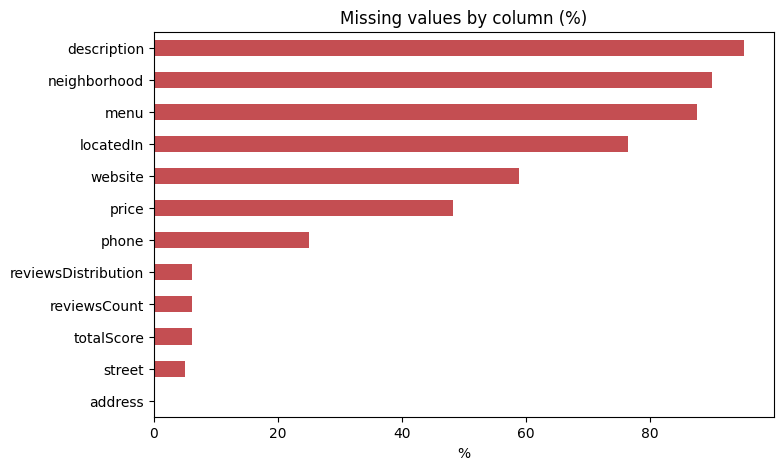

Places: 684 | columns: 32
Closed places: 0
Places without a rating/score: 42
Repeated names (possible branches): 11
title
papa johns pizza                 5
بيتزا وفطائر الامير              3
أنس الدمشقي                      2
أسماك الأندلس                    2
عم سمير بتاع الفطير              2
اسماك عباد الرحمن                2
savoy restaurant and cafe        2
stereo restaurant & cafe         2
فول وفلافل ماهر                  2
crab house seafood restaurant    2
Name: count, dtype: Int64
Distinct categories: 90


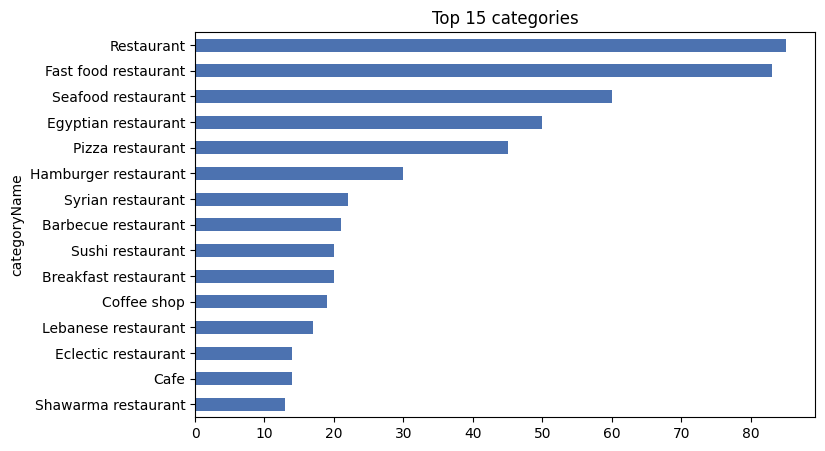

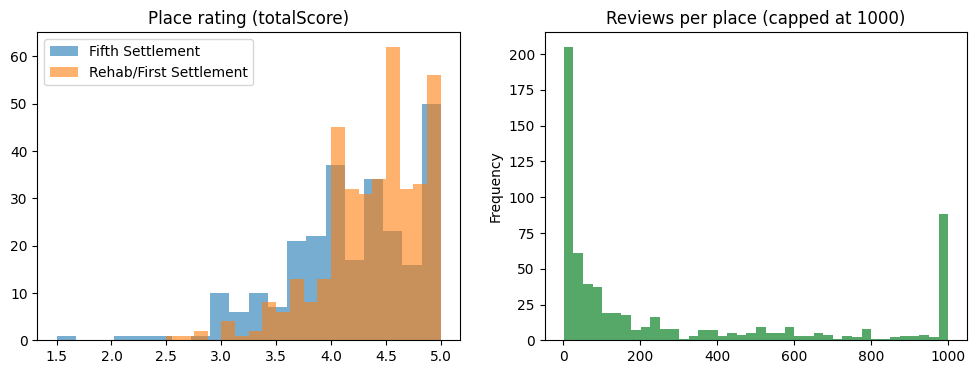

area
Fifth Settlement          4.18
Rehab/First Settlement    4.37
Name: totalScore, dtype: float64


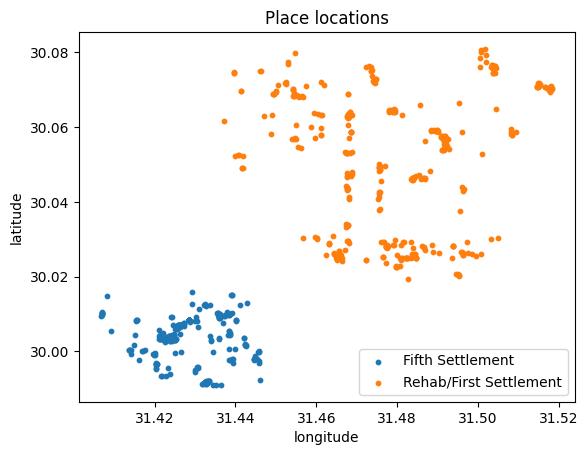

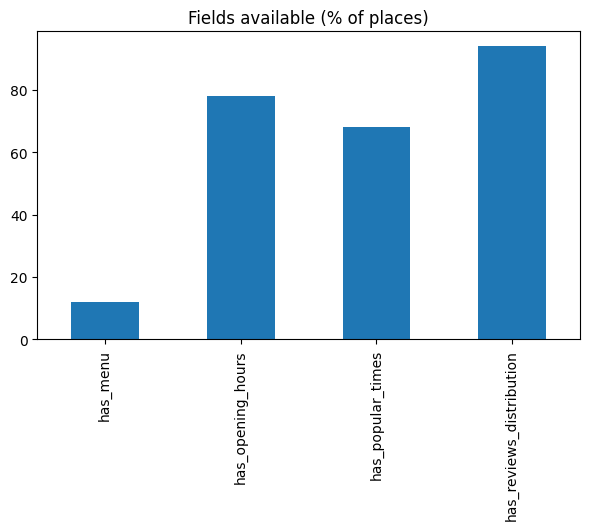

In [27]:
import matplotlib.pyplot as plt

# Area column (Fifth vs Rehab/First)
df_places_clean["area"] = np.where(df_places_clean["source_file"].str.contains("fifth", case=False),
                                   "Fifth Settlement", "Rehab/First Settlement")
print(df_places_clean["area"].value_counts())          # expected 290 / 394

# EDA 1: overview + missing values
miss = df_places_clean.isna().mean().mul(100).round(1).sort_values(ascending=False).head(12)
miss.sort_values().plot(kind="barh", figsize=(8, 5), color="#c44e52")
plt.title("Missing values by column (%)"); plt.xlabel("%"); plt.show()
print("Places:", len(df_places_clean), "| columns:", df_places_clean.shape[1])
print("Closed places:", int(df_places_clean["permanentlyClosed"].fillna(False).sum()))
print("Places without a rating/score:", int(df_places_clean["totalScore"].isna().sum()))

# EDA 2: duplicates and branches
names = df_places_clean["title"].str.lower().str.strip().value_counts()
print("Repeated names (possible branches):", int((names > 1).sum()))
print(names[names > 1].head(10))
# Each placeId is a separate branch, so we keep all of them.

# EDA 3: category distribution (noisy labels)
cat = df_places_clean["categoryName"].value_counts()
print("Distinct categories:", len(cat))
cat.head(15).sort_values().plot(kind="barh", figsize=(8, 5), color="#4c72b0")
plt.title("Top 15 categories"); plt.show()

# EDA 4: ratings and review counts by area
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, g in df_places_clean.groupby("area"):
    ax[0].hist(g["totalScore"].dropna(), bins=20, alpha=0.6, label=a)
ax[0].set_title("Place rating (totalScore)"); ax[0].legend()
df_places_clean["reviewsCount"].clip(upper=1000).plot(kind="hist", bins=40, ax=ax[1], color="#55a868")
ax[1].set_title("Reviews per place (capped at 1000)"); plt.show()
print(df_places_clean.groupby("area")["totalScore"].mean().round(2))

# EDA 5: location map
for a, g in df_places_clean.groupby("area"):
    plt.scatter(g["longitude"], g["latitude"], s=10, label=a)
plt.legend(); plt.title("Place locations"); plt.xlabel("longitude"); plt.ylabel("latitude"); plt.show()

# EDA 6: field availability
avail = df_places_clean[["has_menu", "has_opening_hours", "has_popular_times", "has_reviews_distribution"]].mean().mul(100).round(0)
avail.plot(kind="bar", figsize=(7, 4)); plt.title("Fields available (% of places)"); plt.show()

In [28]:
import json
from google.colab import files

# Excel cannot store lists or dicts, so convert them to text first
def flat(v):
    return json.dumps(v, ensure_ascii=False) if isinstance(v, (list, dict)) else v

x = df_places_clean.copy()
for c in x.columns:
    if x[c].dtype == "object":
        x[c] = x[c].map(flat)

out = "restaurants_metadata_clean.xlsx"
with pd.ExcelWriter(out, engine="openpyxl") as w:
    x.to_excel(w, sheet_name="places_clean", index=False)
    x["area"].value_counts().rename_axis("area").reset_index(name="places") \
        .to_excel(w, sheet_name="by_area", index=False)
    x["categoryName"].value_counts().rename_axis("category").reset_index(name="places") \
        .to_excel(w, sheet_name="categories", index=False)
    (x.isna().mean() * 100).round(1).sort_values(ascending=False) \
        .rename_axis("column").reset_index(name="missing_pct") \
        .to_excel(w, sheet_name="missing_values", index=False)

print("saved", out, "| places:", len(x))
files.download(out)        # downloads the file to his computer

saved restaurants_metadata_clean.xlsx | places: 684


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>